In [15]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Cruz_Fraud Detection/online-payments.csv")
df


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.00,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.00,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.00,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.00,C2080388513,0.00,0.00,1,0


type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


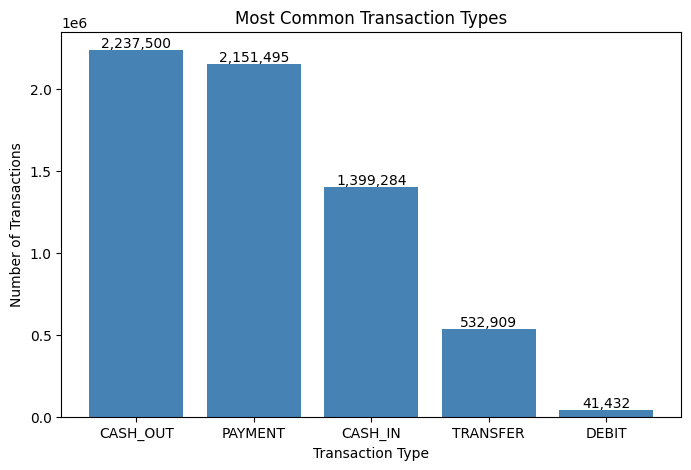

Fraud rate per transaction type
            count  fraud_cases  fraud_rate
type                                      
CASH_IN   1399284            0    0.000000
CASH_OUT  2237500         4116    0.001840
DEBIT       41432            0    0.000000
PAYMENT   2151495            0    0.000000
TRANSFER   532909         4097    0.007688

Amount statistics by class (0 = legit, 1 = fraud)
             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  

Fraud rate when origin account is fully drained vs not
False    0.000032
True     1.000000
Name: isFraud, dtype: float64

Fraud rate when destination balance 

In [16]:
import matplotlib.pyplot as plt

type_counts = df["type"].value_counts()
print(type_counts)

plt.figure(figsize=(8, 5))
bars = plt.bar(type_counts.index, type_counts.values, color="steelblue")
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
plt.title("Most Common Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

print("Fraud rate per transaction type")
print(df.groupby("type")["isFraud"].agg(["count", "sum", "mean"]).rename(columns={"sum": "fraud_cases", "mean": "fraud_rate"}))

print("\nAmount statistics by class (0 = legit, 1 = fraud)")
print(df.groupby("isFraud")["amount"].describe())

drained = (df["oldbalanceOrg"] > 0) & (df["newbalanceOrig"] == 0) & (df["amount"] == df["oldbalanceOrg"])
print("\nFraud rate when origin account is fully drained vs not")
print(df.groupby(drained)["isFraud"].mean())

dest_unchanged = (df["amount"] > 0) & (df["oldbalanceDest"] == df["newbalanceDest"])
print("\nFraud rate when destination balance is unchanged vs changed")
print(df.groupby(dest_unchanged)["isFraud"].mean())

print("\nFlagged by bank rule:", df["isFlaggedFraud"].sum(), "| Actual frauds:", df["isFraud"].sum())

In [17]:
df = df.drop(["nameOrig", "nameDest"], axis=1)

df = pd.get_dummies(df, columns=["type"], drop_first=True)
df

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.00,160296.36,0.00,0.00,0,0,False,False,True,False
1,1,1864.28,21249.00,19384.72,0.00,0.00,0,0,False,False,True,False
2,1,181.00,181.00,0.00,0.00,0.00,1,0,False,False,False,True
3,1,181.00,181.00,0.00,21182.00,0.00,1,0,True,False,False,False
4,1,11668.14,41554.00,29885.86,0.00,0.00,0,0,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,339682.13,339682.13,0.00,0.00,339682.13,1,0,True,False,False,False
6362616,743,6311409.28,6311409.28,0.00,0.00,0.00,1,0,False,False,False,True
6362617,743,6311409.28,6311409.28,0.00,68488.84,6379898.11,1,0,True,False,False,False
6362618,743,850002.52,850002.52,0.00,0.00,0.00,1,0,False,False,False,True


isFraud
0    6354407
1       8213
Name: count, dtype: int64


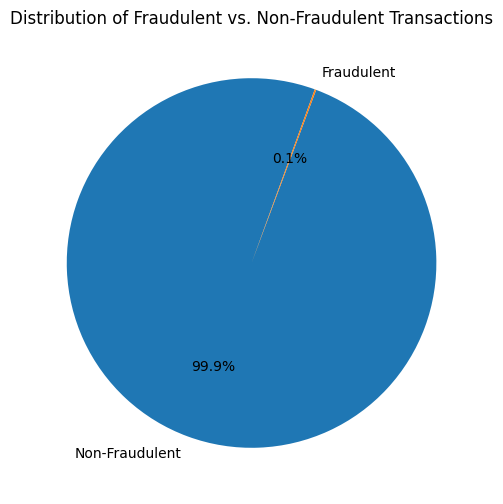

In [10]:
import matplotlib.pyplot as plt

fraud_count = df['isFraud'].value_counts()
print(fraud_count)

plt.figure(figsize=(6, 6))
plt.pie(fraud_count, labels=["Non-Fraudulent", "Fraudulent"], autopct='%1.1f%%', startangle=70)
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions')
plt.show()


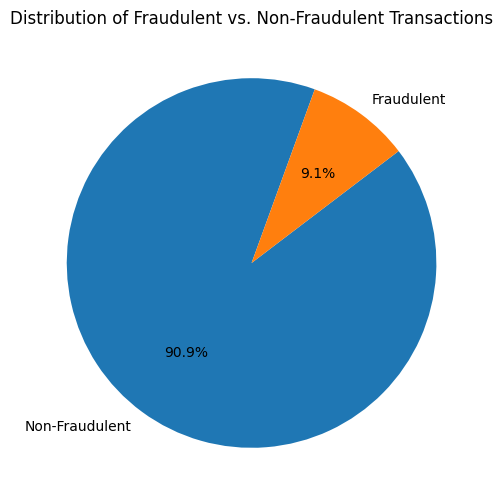

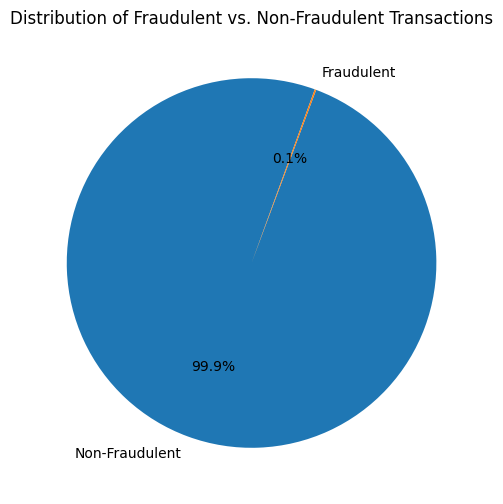

In [65]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df.drop("isFraud", axis=1)
y = df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

rus = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

X_train_resampled_df = pd.DataFrame(X_train_resampled, columns=X.columns)
y_train_resampled_df = pd.Series(y_train_resampled, name='isFraud')

df_train_resampled = pd.concat([X_train_resampled_df, y_train_resampled_df], axis=1)
df_train = pd.concat([X, y], axis=1)

#piechart ng xtrainresampledf at y_trainresampledf, compare sa piechart sa taas
plt.figure(figsize=(6, 6))
plt.pie(df_train_resampled["isFraud"].value_counts(), labels=["Non-Fraudulent", "Fraudulent"], autopct='%1.1f%%', startangle=70)
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions')
plt.figure(figsize=(6, 6))
plt.pie(fraud_count, labels=["Non-Fraudulent", "Fraudulent"], autopct='%1.1f%%', startangle=70)
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions')
plt.show()

#

In [117]:
model_resampled = AdaBoostClassifier(
    n_estimators=3,
    learning_rate=0.05,
    random_state=10
)

model_resampled.fit(X_train_resampled, y_train_resampled)
y_pred_resampled = model_resampled.predict(X_test)

In [118]:
print("Classification Report")

print(classification_report(y_test, y_pred_resampled))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_resampled))

print("\nAccuracy Score")
print(accuracy_score(y_test, y_pred_resampled))

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99   1906322
           1       0.02      0.37      0.03      2464

    accuracy                           0.97   1908786
   macro avg       0.51      0.67      0.51   1908786
weighted avg       1.00      0.97      0.98   1908786


Confusion Matrix
[[1852193   54129]
 [   1548     916]]

Accuracy Score
0.9708311984685554


In [26]:
import time

start_time = time.time()

y_pred = model_resampled.predict(X_test)

prediction_time = time.time() - start_time

print(f"Prediction Time: {prediction_time:.4f} seconds")
#

Prediction Time: 3.0364 seconds
